# ClusterBP v2: проверка на отложенных регионах

Переносится ли модель в регионы, которых не было при обучении (другие медицинские организации, практика наблюдения, приборы)?

- 19 регионов делятся на 5 групп (StratifiedGroupKFold с группой = регион); модель обучается на пациентах четырёх групп и проверяется на регионах пятой;
- внутри обучающих регионов 20% пациентов — внутренняя валидация (ранняя остановка, пороги, стекинг);
- фенотипы GDTW строятся только по пациентам обучающих регионов;
- модели и признаки те же, что в `clusterbp_v2.ipynb`; итоговая модель — стекинг GRU и XGB_full.

Для сравнения приводятся результаты обычной кросс-валидации по пациентам.

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

from clusterbp_lib import (DATA_DIR, CACHE_DIR, RESULTS_DIR, SEED, TARGETS, FEATURE_SETS, N_FOLDS, INNER_VAL_FRAC,
                           load_regions, fit_phenotypes, assign_phenotypes, set_phenotype_columns, fit_xgb, train_gru,
                           gru_logits, sigmoid, logit, best_threshold, boot_eval, ci)

warnings.filterwarnings('ignore')
torch.set_num_threads(os.cpu_count())
REGION_TARGETS = ['A', 'B']
FULL = FEATURE_SETS['full']

win = pd.read_parquet(os.path.join(DATA_DIR, 'windows.parquet'))
X_seq = np.load(os.path.join(DATA_DIR, 'X_seq.npy'))
seq_len = np.load(os.path.join(DATA_DIR, 'seq_len.npy'))
pheno_win = np.load(os.path.join(DATA_DIR, 'pheno_win.npy'))
pheno_first = np.load(os.path.join(DATA_DIR, 'pheno_first.npy'))
pheno_first_pid = np.load(os.path.join(DATA_DIR, 'pheno_first_pid.npy'))
oof_cv = pd.read_parquet(os.path.join(CACHE_DIR, 'oof_moe.parquet'))

regions = load_regions()
win['region'] = regions.reindex(win['pid'].values).fillna('неизвестно').values
pid = win['pid'].values
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
rfold = np.full(len(win), -1)
for k, (_, te) in enumerate(sgkf.split(win, win['y_A'], groups=win['region'].values)):
    rfold[te] = k
win['rfold'] = rfold
summary = win.groupby('rfold').agg(регионов=('region', 'nunique'), пациентов=('pid', 'nunique'), окон=('pid', 'size'),
                                  доля_A=('y_A', 'mean'), доля_B=('y_B', 'mean'))
summary['регионы'] = win.groupby('rfold')['region'].apply(lambda s: ', '.join(sorted(s.unique())))
summary

,регионов,пациентов,окон,доля_A,доля_B,регионы
rfold,,,,,,
0,1,1509,88060,0.044333,0.134908,Тюменская область
1,5,1758,85198,0.041351,0.107890,"Волгоградская область, Кемеровская область, Ко..."
2,3,1662,81781,0.048850,0.143358,"Алтайский край, Ростовская область, Ханты-Манс..."
3,3,2427,85549,0.048534,0.127319,"Красноярский край, Московская область, Тульска..."
4,7,2057,79767,0.050184,0.140935,"Воронежская область, Забайкальский край, Курск..."


In [2]:
preds = {t: {m: np.full(len(win), np.nan) for m in ['XGB_full', 'GRU', 'Stack']} for t in REGION_TARGETS}
pred_bin = {t: {m: np.zeros(len(win), np.int8) for m in ['XGB_full', 'GRU', 'Stack']} for t in REGION_TARGETS}
t_all = time.time()
for k in range(N_FOLDS):
    te = rfold == k
    train_pids = np.unique(pid[~te])
    rng = np.random.default_rng(SEED + k)
    val_pids = rng.choice(train_pids, int(len(train_pids) * INNER_VAL_FRAC), replace=False)
    va = ~te & np.isin(pid, val_pids)
    tr = ~te & ~va
    templates, _, _ = fit_phenotypes(pheno_first, pheno_first_pid, train_pids, SEED + k)
    cl, dist = assign_phenotypes(pheno_win, templates)
    set_phenotype_columns(win, cl, dist)
    X = win[FULL].values
    for t in REGION_TARGETS:
        y = win[f'y_{t}'].values
        xm = fit_xgb(X[tr], y[tr], X[va], y[va], SEED + k)
        px = xm.predict_proba(X)[:, 1]
        gm, mu, sd, corr, _ = train_gru(X_seq[tr], seq_len[tr], y[tr], X_seq[va], seq_len[va], y[va], SEED + k)
        pg = sigmoid(gru_logits(gm, X_seq, seq_len, mu, sd) + corr)
        stack = LogisticRegression(max_iter=3000).fit(np.column_stack([logit(pg[va]), logit(px[va])]), y[va])
        ps = stack.predict_proba(np.column_stack([logit(pg), logit(px)]))[:, 1]
        for m, s in [('XGB_full', px), ('GRU', pg), ('Stack', ps)]:
            thr, _ = best_threshold(y[va], s[va])
            preds[t][m][te] = s[te]
            pred_bin[t][m][te] = s[te] > thr
    print(f'Группа регионов {k}: {(time.time() - t_all) / 60:.1f} мин')

Группа регионов 0: 2.2 мин


Группа регионов 1: 4.7 мин


Группа регионов 2: 7.3 мин


Группа регионов 3: 9.8 мин


Группа регионов 4: 12.5 мин


## Результаты

Сверху — объединённые предсказания по всем отложенным регионам (95% ДИ — бутстреп по пациентам) рядом с обычной кросс-валидацией по пациентам; снизу — каждый регион отдельно.

,target,model,AUROC,AUPRC,AUPRC 95% ДИ,macro_F1,"AUPRC, CV по пациентам"
0,A,ClusterBP v2 (стекинг),0.898,0.454,[0.425; 0.481],0.716,0.451
1,A,XGB_full,0.896,0.450,[0.421; 0.477],0.715,NaN
2,A,GRU,0.875,0.407,[0.378; 0.433],0.700,NaN
3,B,ClusterBP v2 (стекинг),0.910,0.677,[0.660; 0.693],0.783,0.678
4,B,XGB_full,0.909,0.675,[0.657; 0.691],0.783,NaN
5,B,GRU,0.894,0.642,[0.625; 0.659],0.773,NaN


,target,регион,пациентов,окон,доля событий,AUPRC ClusterBP v2,AUROC ClusterBP v2,AUPRC / доля событий
12,A,Тюменская область,1509,88060,0.044,0.451,0.899,10.177
1,A,Волгоградская область,1027,55885,0.041,0.412,0.893,9.985
13,A,Ханты-Мансийский автономный округ — Югра,1022,45157,0.053,0.561,0.919,10.626
7,A,Московская область,1235,44733,0.051,0.433,0.897,8.438
8,A,Новосибирская область,1156,42658,0.050,0.437,0.885,8.740
2,A,Воронежская область,595,29904,0.056,0.435,0.877,7.815
11,A,Тульская область,735,24224,0.047,0.528,0.914,11.197
9,A,Ростовская область,365,19290,0.043,0.429,0.904,10.011
3,A,Кемеровская область,368,19200,0.047,0.388,0.871,8.301
0,A,Алтайский край,275,17334,0.045,0.368,0.895,8.105


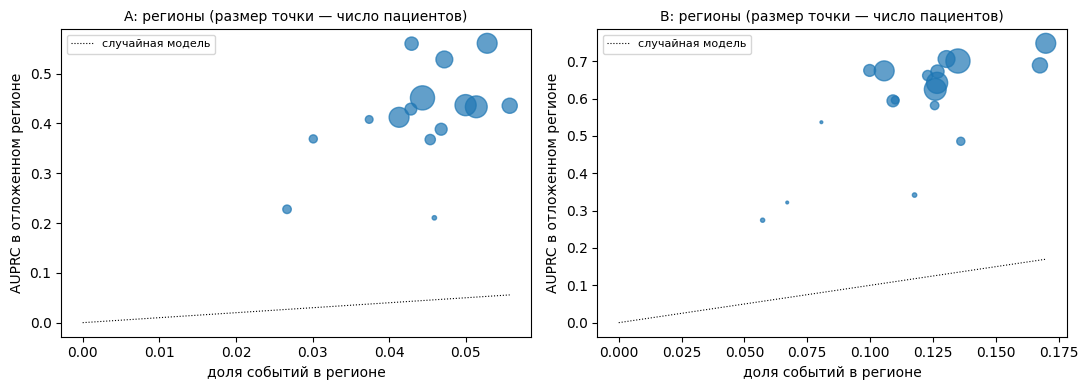

In [3]:
rows = []
for t in REGION_TARGETS:
    y = win[f'y_{t}'].values.astype(float)
    models = [(preds[t][m], pred_bin[t][m].astype(float)) for m in ['Stack', 'XGB_full', 'GRU']]
    B = boot_eval(y, pid, models, n_boot=1000)
    cv_map = {'Stack': 'Stack_global', 'XGB_full': 'XGB_full', 'GRU': 'GRU'}
    for j, m in enumerate(['Stack', 'XGB_full', 'GRU']):
        cv_scores = oof_cv[f'{t}__{cv_map[m]}__score'].values if f'{t}__{cv_map[m]}__score' in oof_cv else None
        rows.append({'target': t, 'model': 'ClusterBP v2 (стекинг)' if m == 'Stack' else m,
                     'AUROC': roc_auc_score(y, preds[t][m]), 'AUPRC': average_precision_score(y, preds[t][m]),
                     'AUPRC 95% ДИ': ci(B[:, j, 1]), 'macro_F1': f1_score(y, pred_bin[t][m], average='macro'),
                     'AUPRC, CV по пациентам': average_precision_score(y, cv_scores) if cv_scores is not None else np.nan})
pooled = pd.DataFrame(rows)
pooled.to_csv(os.path.join(RESULTS_DIR, 'regions_pooled.csv'), index=False)
display(pooled.round(3))

rows = []
for t in REGION_TARGETS:
    y = win[f'y_{t}'].values
    for r, idx in win.groupby('region').indices.items():
        if y[idx].sum() < 20:
            continue
        rows.append({'target': t, 'регион': r, 'пациентов': len(np.unique(pid[idx])), 'окон': len(idx),
                     'доля событий': y[idx].mean(),
                     'AUPRC ClusterBP v2': average_precision_score(y[idx], preds[t]['Stack'][idx]),
                     'AUROC ClusterBP v2': roc_auc_score(y[idx], preds[t]['Stack'][idx]),
                     'AUPRC / доля событий': average_precision_score(y[idx], preds[t]['Stack'][idx]) / y[idx].mean()})
by_region = pd.DataFrame(rows).sort_values(['target', 'окон'], ascending=[True, False])
by_region.to_csv(os.path.join(RESULTS_DIR, 'regions_by_region.csv'), index=False)
display(by_region.round(3))

fig, axes = plt.subplots(1, len(REGION_TARGETS), figsize=(11, 4))
for ax, t in zip(axes, REGION_TARGETS):
    sub = by_region[by_region.target == t]
    ax.scatter(sub['доля событий'], sub['AUPRC ClusterBP v2'], s=sub['пациентов'] / 5, alpha=0.7)
    ax.plot([0, sub['доля событий'].max()], [0, sub['доля событий'].max()], 'k:', lw=0.8, label='случайная модель')
    ax.set_xlabel('доля событий в регионе'); ax.set_ylabel('AUPRC в отложенном регионе')
    ax.set_title(f'{t}: регионы (размер точки — число пациентов)', fontsize=10)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'regions.png'), dpi=200, bbox_inches='tight')
plt.show()